# GEOL 557A Group Project: Data Wrangling

**Team:** Brock Drengenberg, Hsu Kyi, Amanda Kelley-Teng

**Question:** How do external forcing (CO2 and volcanic aerosols) and internal variability (ENSO) shape global temperature, and are today's CO2 level and rate of change outside the natural range of the last 800,000 years?

Our concept map has three branches. The deep-time branch produces one clean table. The modern-observation and volcanic branches share a second table on a common 1850 to 2025 year index. Brock collected the ice-core files, and the modern and volcanic workflow builds on Hsu's Colab notebook.

| Concept-map branch | Span | Raw data files | Clean table |
|---|---|---|---|
| Deep time: CO2 and temperature | ~801,000 yr BP to 1911 CE | `antarctica2015co2.xls` (ice-core CO2); `edc3deuttemp2007.txt` (EPICA Dome C temperature) | `deep_time_co2_temp.csv` |
| Modern observations: temperature, CO2, ENSO | 1850 to 2025 | HadCRUT5 temperature; `law2006.csv` and `co2_annmean_mlo.csv` (CO2); `nino34.long.anom.csv` (ENSO) | `modern_climate_1850_2025.csv` |
| Volcanic event records | 1850 to 2025 | `tau.line_2012.12.txt` (aerosol optical depth); `GEOL557_Volcano_Catalog.csv` (eruptions) | `modern_climate_1850_2025.csv` (shared with modern observations) |

The notebook follows the wrangling in order: what the original files look like, how we cleaned them, how we transformed them onto shared units and time axes, what the clean tables look like, and descriptive statistics and plots of the result.

**Setup:** reading `.xls` workbooks needs the `xlrd` package (`pip install xlrd`; Colab already has it). Run the notebook from the `notebook/` folder so the `../data` paths resolve.

In [1]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW = Path("../data/raw")
CLEAN = Path("../data/clean")
CLEAN.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

# Plot colors: using a colorblind-checked categorical set, plus muted axes and gridlines.
BLUE, ORANGE, RED, GRAY, INK = "#2a78d6", "#eb6834", "#e34948", "#898781", "#52514e"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRAY, "axes.labelcolor": INK, "axes.titlecolor": INK,
    "xtick.color": GRAY, "ytick.color": GRAY,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "figure.dpi": 110,
})
print("pandas", pd.__version__)

from pathlib import Path

print("Current working directory:", Path.cwd())
print("Looking for data in:", RAW.resolve())
print("Does the raw folder exist?", RAW.exists())
print("Does the CO2 file exist?", (RAW / "antarctica2015co2.xls").exists())

pandas 2.3.3
Current working directory: /Users/aekelley/code/Jupyter/GEOL557_group_project/notebook
Looking for data in: /Users/aekelley/code/Jupyter/GEOL557_group_project/data/raw
Does the raw folder exist? True
Does the CO2 file exist? True


---
## The original data


### Ice-core CO2 (`antarctica2015co2.xls`)

NOAA study 17975, a composite of Antarctic ice-core CO2 records. The workbook has three sheets: `Readme`, `all records` (20 separate ice-core records side by side) and `CO2 Composite` (the merged 0 to 806 kyr series we use). The composite sheet has 14 rows of notes above its column header, so we print it row by row exactly as stored.

In [2]:
co2_path = RAW / "antarctica2015co2.xls"
sheets = pd.read_excel(co2_path, sheet_name=None, header=None)
for name, sheet in sheets.items():
    print(f"sheet '{name}': {sheet.shape[0]} rows x {sheet.shape[1]} columns")

co2_sheet = sheets["CO2 Composite"]
print("\nFirst 17 rows of 'CO2 Composite':")
for i in range(17):
    print(f"row {i:2d}: " + " | ".join(str(v) for v in co2_sheet.iloc[i].dropna()))

sheet 'Readme': 134 rows x 3 columns
sheet 'all records': 399 rows x 108 columns
sheet 'CO2 Composite': 1916 rows x 3 columns

First 17 rows of 'CO2 Composite':
row  0: Composite CO2 record (0-800 kyr BP)
row  1: -51-1800 yr BP:' | Law Dome (Rubino et al., 2013)
row  2: 1.8-2 kyr BP: | Law Dome (MacFarling Meure et al., 2006)
row  3: 2-11 kyr BP: | Dome C (Monnin et al., 2001 + 2004)
row  4: 11-22 kyr BP: | WAIS (Marcott et al., 2014) minus 4 ppmv (see text)
row  5: 22-40 kyr BP: | Siple Dome (Ahn et al., 2014)
row  6: 40-60 kyr BP: | TALDICE (Bereiter et al., 2012)
row  7: 60-115 kyr BP: | EDML (Bereiter et al., 2012)
row  8: 105-155 kyr BP: | Dome C Sublimation (Schneider et al., 2013)
row  9: 155-393 kyr BP: | Vostok (Petit et al., 1999)
row 10: 393-611 kyr BP: | Dome C (Siegenthaler et al., 2005)
row 11: 612-800 kyr BP: | Dome C (Bereiter et al., 2014)
row 12: Gasage: AICC2012 (Bazin et al., 2013) except for Law Dome, WAIS and Siple Dome (see text for more details).
row 13: Sigma: 

### EPICA Dome C temperature (`edc3deuttemp2007.txt`)

NOAA study 6080. A text file with a 118-line metadata header, then tab-delimited data with `NA` for missing values.

In [3]:
edc_path = RAW / "edc3deuttemp2007.txt"
edc_lines = edc_path.read_text(encoding="utf-8").splitlines()
edc_hdr = next(i for i, line in enumerate(edc_lines) if line.startswith("Bag"))
print(f"{len(edc_lines)} lines; the column header is on line {edc_hdr}\n")
print("\n".join(edc_lines[:3]))
print("...")
print("\n".join(edc_lines[edc_hdr:edc_hdr + 6]))
print("...")
print("\n".join(edc_lines[-3:]))

5919 lines; the column header is on line 118

# EPICA Dome C - 800KYr Deuterium Data and Temperature Estimates
#----------------------------------------------------
#                World Data Service for Paleoclimatology, Boulder
...
Bag	depth_top_m	age_calBP	Deuterium	Temperature
1	0	-50.00000	NA	NA
2	0.55	-43.54769	NA	NA
3	1.1	-37.41829	NA	NA
4	1.65	-31.61153	NA	NA
5	2.2	-24.51395	NA	NA
...
5798	3188.35	799501	-441.1	-8.88
5799	3188.9	800589	-441.42	-8.92
5800	3189.45	801662	-440.9	-8.82


### Modern records

* `HadCRUT.5.2.0.0.analysis.summary_series.global.annual.csv`: Met Office HadCRUT5. Global annual temperature anomaly with 95% confidence limits, 1850 on.
* `law2006.csv`: Law Dome ice core. Annual CO2 spline through 2004.
* `co2_annmean_mlo.csv`: NOAA GML, Mauna Loa. Annual CO2, 1959 on.
* `nino34.long.anom .csv`: NOAA PSL Niño 3.4 long anomaly series. Monthly ENSO index, 1870 on.
* `tau.line_2012.12.txt`: NASA GISS. Monthly stratospheric aerosol optical depth at 550 nm, 1850 to September 2012.
* `GEOL557_Volcano_Catalog.csv`: Smithsonian Global Volcanism Program (Hsu's selection). 17 eruptions, VEI 3 to 6, 1854 to 1991.

In [4]:
# The downloaded ENSO file name has a stray space before ".csv"; accept either spelling.
ENSO_FILE = next(p for p in [RAW / "nino34.long.anom.csv", RAW / "nino34.long.anom .csv"] if p.exists())
aod_path = RAW / "tau.line_2012.12.txt"

hadcrut_raw = pd.read_csv(RAW / "HadCRUT.5.2.0.0.analysis.summary_series.global.annual.csv")
law_raw = pd.read_csv(RAW / "law2006.csv")
mlo_raw = pd.read_csv(RAW / "co2_annmean_mlo.csv")
enso_raw = pd.read_csv(ENSO_FILE)
volc_raw = pd.read_csv(RAW / "GEOL557_Volcano_Catalog.csv")

print("".join(aod_path.read_text().splitlines(keepends=True)[:6]))

 Global and Hemispheric Mean Aerosol Optical Depth at 550 nm
 -----------------------------------------------------------
   
year/mon  global N.Hemis S.Hemis
1850.042  0.0044  0.0044  0.0044
1850.125  0.0042  0.0042  0.0042



In [5]:
modern_raw = {"HadCRUT5": hadcrut_raw, "Law Dome": law_raw, "Mauna Loa": mlo_raw,
              "ENSO": enso_raw, "Volcano catalog": volc_raw}
for label, df in modern_raw.items():
    print(f"=== {label}: {df.shape[0]} rows x {df.shape[1]} columns")
    print(df.head(3).to_string(), "\n")
    df.info()
    print()

=== HadCRUT5: 177 rows x 4 columns
   Time  Anomaly (deg C)  Lower confidence limit (2.5%)  Upper confidence limit (97.5%)
0  1850        -0.426778                      -0.599831                       -0.253725
1  1851        -0.258487                      -0.432716                       -0.084257
2  1852        -0.224383                      -0.388887                       -0.059880 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 177 entries, 0 to 176
Data columns (total 4 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Time                            177 non-null    int64  
 1   Anomaly (deg C)                 177 non-null    float64
 2   Lower confidence limit (2.5%)   177 non-null    float64
 3   Upper confidence limit (97.5%)  177 non-null    float64
dtypes: float64(3), int64(1)
memory usage: 5.7 KB

=== Law Dome: 2004 rows x 9 columns
   rownames  year  NOAA04  CH4_spl  CH4_grw  CO2_spl  

In [6]:
for label in ["HadCRUT5", "ENSO"]:
    print(f"=== {label}")
    print(modern_raw[label].describe().T.round(3).to_string(), "\n")

=== HadCRUT5
                                count      mean     std       min       25%       50%       75%       max
Time                            177.0  1938.000  51.240  1850.000  1894.000  1938.000  1982.000  2026.000
Anomaly (deg C)                 177.0    -0.052   0.410    -0.597    -0.340    -0.168     0.108     1.187
Lower confidence limit (2.5%)   177.0    -0.145   0.446    -0.727    -0.477    -0.251     0.065     1.145
Upper confidence limit (97.5%)  177.0     0.041   0.376    -0.470    -0.205    -0.073     0.174     1.230 

=== ENSO
                                                                           count    mean      std     min   25%   50%   75%   max
NINA34  missing value -99.99 https://psl.noaa.gov/data/timeseries/month/  1884.0 -16.016  398.789 -9999.0 -0.64 -0.16  0.35  2.63 



`describe()` on the raw files already shows two problems. The ENSO minimum is -9999, which is a placeholder, not a temperature. HadCRUT5 also runs to 2026, which is still a partial year.

---
## Data cleansing

Check for wrong formats, bad labels, incorrect values, missing values, duplicates and bias.

### Wrong format

Three files can't be read with a plain `read_csv` or `read_excel`:
- The CO2 composite sheet has note rows above the real header.
- The EDC file has a long metadata header and writes missing values as the text `NA`.
- The AOD file has a title block and a header that doesn't split cleanly into columns.

ENSO also loads with the wrong type: its dates are stored as text. We find each header row by its text instead of hard-coding a row number, so the code still works if a file gains or loses a note line.

In [7]:
# "Gasage (yr" rather than "Gasage", because the note on row 12 also starts with "Gasage:".
co2_hdr = co2_sheet.index[co2_sheet[0].astype(str).str.startswith("Gasage (yr")][0]
ice_co2 = pd.read_excel(co2_path, sheet_name="CO2 Composite", skiprows=co2_hdr)

# sep=r"\s+" handles tabs and runs of spaces; na_values turns the text "NA" into NaN so the columns load as numbers.
edc = pd.read_csv(edc_path, skiprows=edc_hdr, sep=r"\s+", na_values="NA")

aod = pd.read_csv(aod_path, sep=r"\s+", skiprows=4, header=None,
                  names=["decimal_year", "global_aod", "nh_aod", "sh_aod"])

enso = enso_raw.copy()
enso["Date"] = pd.to_datetime(enso["Date"])

# Excel headers carry stray spaces ("Gasage (yr BP) "), which would make the renames below miss silently.
ice_co2.columns = ice_co2.columns.str.strip()

print("Header rows found -> CO2 composite:", co2_hdr, "| EDC:", edc_hdr)
for label, df in [("CO2 composite", ice_co2), ("EDC", edc), ("AOD", aod), ("ENSO", enso)]:
    print(f"\n{label} ({len(df)} rows)")
    print(df.dtypes.to_string())

Header rows found -> CO2 composite: 14 | EDC: 118

CO2 composite (1901 rows)
Gasage (yr BP)           float64
CO2 (ppmv)               float64
sigma mean CO2 (ppmv)    float64

EDC (5800 rows)
Bag              int64
depth_top_m    float64
age_calBP      float64
Deuterium      float64
Temperature    float64

AOD (1953 rows)
decimal_year    float64
global_aod      float64
nh_aod          float64
sh_aod          float64

ENSO (1884 rows)
Date                                                                           datetime64[ns]
   NINA34  missing value -99.99 https://psl.noaa.gov/data/timeseries/month/           float64


### Cleaning up the labels

- Column names mix spaces, units and symbols (`sigma mean CO2 (ppmv)`, `Anomaly (deg C)`).
- The ENSO value column's header is a note, not a name: `NINA34  missing value -99.99 https://...`. The missing-value code it gives is also wrong (see Incorrect values).
- One volcano name, `Cotopaxi (1855–1856)`, has its eruption dates in the name.

We rename the columns to short snake_case with the unit in the name, so the analysis can read them without going back to the source documentation.

In [8]:
ice_co2 = ice_co2.rename(columns={
    "Gasage (yr BP)": "age_bp",               # gas age, years before 1950
    "CO2 (ppmv)": "co2_ppm",
    "sigma mean CO2 (ppmv)": "co2_1sigma_ppm",
})
edc = edc.rename(columns={
    "Bag": "bag", "depth_top_m": "depth_m", "age_calBP": "age_bp",
    "Deuterium": "deuterium_permil",
    "Temperature": "temp_anomaly_c",          # relative to the mean of the last 1,000 years
})

hadcrut = hadcrut_raw.rename(columns={
    "Time": "year", "Anomaly (deg C)": "anom_6190_c",   # relative to 1961-1990
    "Lower confidence limit (2.5%)": "ci_low_6190_c", "Upper confidence limit (97.5%)": "ci_high_6190_c"})
law = law_raw[["year", "CO2_spl"]].rename(columns={"CO2_spl": "co2_ppm"})
mlo = mlo_raw.rename(columns={"Year": "year", "Mean": "co2_ppm"})[["year", "co2_ppm"]]
enso.columns = ["date", "nino34_c"]
volc = volc_raw.rename(columns={"Year": "year", "Volcano": "volcano", "VEI": "vei"})
volc["volcano"] = volc["volcano"].str.replace(r"\s*\(.*\)$", "", regex=True)

print("Volcano names:", volc["volcano"].tolist())

Volcano names: ['Sheveluch', 'Cotopaxi', 'Awu', 'Krakatau', 'Tarawera', 'Mount Pelée', 'Santa Maria', 'Ksudach', 'Novarupta', 'Sakurajima', 'Agung', 'Fernandina', 'Fuego', 'Mount St. Helens', 'El Chichon', 'Nevado del Ruiz', 'Pinatubo']


### Incorrect values

These values are present but wrong or out of scope:
- ENSO marks missing months with -9999, even though its header says -99.99. We replace both codes with NaN.
- HadCRUT5's last row is 2026, an incomplete year, so the table stops at 2025.
- The CO2 composite includes samples from after 1950 (negative ages). The modern table covers those years with annual data, so we drop them here.

The deep-time record still includes samples from 1750 to 1911 CE, when CO2 was already rising from industrial emissions; the youngest is from 1911 at 299.3 ppm. They aren't wrong, and they show the start of the modern rise, so we keep them. But they aren't part of the natural range, so they get an `is_preindustrial` flag (see Encoding). Samples from 1850 on also overlap the modern table.

In [9]:
print("ENSO placeholder values found:", sorted(enso.loc[enso["nino34_c"] < -90, "nino34_c"].unique()))
enso.loc[enso["nino34_c"] <= -99, "nino34_c"] = np.nan    # catches -99.99 and -9999

print("HadCRUT5 years:", hadcrut["year"].min(), "to", hadcrut["year"].max())
hadcrut = hadcrut[hadcrut["year"].between(1850, 2025)].copy()

print("CO2 composite samples after 1950:", int((ice_co2["age_bp"] < 0).sum()))
ice_co2 = ice_co2[ice_co2["age_bp"] >= 0].copy()

ENSO placeholder values found: [np.float64(-9999.0)]
HadCRUT5 years: 1850 to 2026
CO2 composite samples after 1950: 61


A range check confirms the remaining values are physically plausible. Running this check is how we found the ENSO placeholder and the post-1950 CO2 samples above.

In [10]:
range_checks = {
    "ice-core CO2 within 150-320 ppm": ice_co2["co2_ppm"].between(150, 320).all(),
    "Mauna Loa CO2 within 300-450 ppm": mlo["co2_ppm"].between(300, 450).all(),
    "EDC temperature anomaly within -15 to +10 C": edc["temp_anomaly_c"].dropna().between(-15, 10).all(),
    "Nino 3.4 anomaly within -5 to +5 C": enso["nino34_c"].dropna().between(-5, 5).all(),
    "AOD is not negative": (aod["global_aod"] >= 0).all(),
    "HadCRUT5 anomaly inside its own confidence limits":
        ((hadcrut["ci_low_6190_c"] <= hadcrut["anom_6190_c"]) & (hadcrut["anom_6190_c"] <= hadcrut["ci_high_6190_c"])).all(),
}
for name, ok in range_checks.items():
    print("ok  " if ok else "FAIL", name)
assert all(range_checks.values())

ok   ice-core CO2 within 150-320 ppm
ok   Mauna Loa CO2 within 300-450 ppm
ok   EDC temperature anomaly within -15 to +10 C
ok   Nino 3.4 anomaly within -5 to +5 C
ok   AOD is not negative
ok   HadCRUT5 anomaly inside its own confidence limits


### Missing values

EDC is the only deep-time file with gaps (the CO2 composite has none). Its first 12 rows are young firn near the surface with no measurement at all, so we drop them. Three deeper rows are missing only deuterium. We don't use deuterium, so those rows keep their temperature and the column is dropped.

In [11]:
print("EDC missing values:")
print(edc.isna().sum().to_string())
edc = edc.dropna(subset=["temp_anomaly_c"]).reset_index(drop=True)
print("\nRows missing deuterium only:")
print(edc.loc[edc["deuterium_permil"].isna(), ["age_bp", "temp_anomaly_c", "deuterium_permil"]].to_string())
edc = edc[["age_bp", "temp_anomaly_c"]]

print("\nMissing values in the CO2 composite:", int(ice_co2.isna().sum().sum()))

EDC missing values:
bag                  0
depth_m              0
age_bp               0
deuterium_permil    15
temp_anomaly_c      12

Rows missing deuterium only:
         age_bp  temp_anomaly_c  deuterium_permil
157  2219.39380            0.20               NaN
206  3110.29199            0.95               NaN
523  9429.85156            0.36               NaN

Missing values in the CO2 composite: 0


Neither modern CO2 record covers 1850 to 2025 on its own: Law Dome ends in 2004 and Mauna Loa starts in 1959. We splice them, using Law Dome for 1850 to 1958 and Mauna Loa from 1959 on. They overlap from 1959 to 2004, which lets us check the join.

In [12]:
overlap = law.merge(mlo, on="year", suffixes=("_law", "_mlo"))
gap = overlap["co2_ppm_law"] - overlap["co2_ppm_mlo"]
print(f"Law Dome minus Mauna Loa, {overlap.year.min()}-{overlap.year.max()}: "
      f"mean {gap.mean():.2f} ppm, range {gap.min():.2f} to {gap.max():.2f} ppm")

co2_modern = pd.concat([
    law[law["year"].between(1850, 1958)].assign(co2_source="Law Dome ice core"),
    mlo[mlo["year"] >= 1959].assign(co2_source="Mauna Loa"),
], ignore_index=True)
print("Spliced CO2 years:", len(co2_modern), "| 1958 -> 1959:",
      co2_modern.loc[co2_modern.year == 1958, "co2_ppm"].item(), "->",
      co2_modern.loc[co2_modern.year == 1959, "co2_ppm"].item(), "ppm")

Law Dome minus Mauna Loa, 1959-2004: mean -2.33 ppm, range -3.90 to -0.28 ppm
Spliced CO2 years: 176 | 1958 -> 1959: 315.2 -> 315.98 ppm


Law Dome runs about 2.3 ppm below Mauna Loa across the overlap. That's expected: most fossil CO2 is emitted in the Northern Hemisphere, so Mauna Loa (19°N) reads a little higher than Antarctic air. The step at the join is under 1 ppm, small next to the 140 ppm rise since 1850, so we don't adjust either record.

### Duplicates

We check every table for repeated time stamps. A repeat would mean either two measurements of the same moment or a data-entry error.

In [13]:
for label, df, key in [("CO2 composite", ice_co2, "age_bp"), ("EDC", edc, "age_bp"),
                       ("HadCRUT5", hadcrut, "year"),
                       ("Spliced CO2", co2_modern, "year"), ("ENSO", enso, "date"),
                       ("AOD", aod, "decimal_year"), ("Volcano catalog", volc, "year")]:
    print(f"{label:16s} repeated {key}: {df[key].duplicated().sum()}")
print("\nFully duplicated volcano rows:", volc.duplicated().sum())
print(volc[volc["year"].duplicated(keep=False)].to_string(index=False))

CO2 composite    repeated age_bp: 0
EDC              repeated age_bp: 0
HadCRUT5         repeated year: 0
Spliced CO2      repeated year: 0
ENSO             repeated date: 0
AOD              repeated decimal_year: 0
Volcano catalog  repeated year: 1

Fully duplicated volcano rows: 0
 year     volcano  vei
 1902 Mount Pelée    4
 1902 Santa Maria    6


None of the measurement tables have repeated time stamps. The one repeated year in the volcano catalog is real: Mount Pelée and Santa Maria both erupted in 1902. 

### Biased data

Bias here means the data over- or under-represents part of what we want to study. We can't remove it during wrangling, but we can measure it and carry it into the analysis.

- **Uneven sampling in time.** CO2 samples are much denser near the present than in older ice (see the spacing chart below). Any statistic computed per row, such as a mean, a correlation or the glacial/interglacial split, gives the Holocene far more weight than its share of time. The analysis should average onto an even time grid before computing statistics for the whole 800,000 years.
- **A hand-picked eruption list.** The catalog has 17 eruptions from 1854 to 1991. GVP lists other VEI 4+ eruptions in this window, and nothing after 1991 is included (for example Puyehue-Cordón Caulle in 2011 and Hunga Tonga in 2022). So in the clean table, `eruption_flag = 0` means "not in our list", not "no eruption". Volcanic AOD measures the aerosol load directly, so it is the better predictor of cooling.

In [14]:
print("Volcano catalog:", len(volc), "eruptions,", volc.year.min(), "to", volc.year.max(),
      "| eruptions by VEI:", volc["vei"].value_counts().sort_index().to_dict())

Volcano catalog: 17 eruptions, 1854 to 1991 | eruptions by VEI: {3: 2, 4: 5, 5: 6, 6: 4}


---
## Transformations


### Different units

The records keep time in different units. Ice-core ages are years before 1950 (BP); ENSO uses monthly dates and AOD uses decimal years. Every modern record gets an integer calendar `year`, and the deep-time table also gets `age_kyr` (thousands of years BP) for plotting. CO2 is converted from ppm to radiative forcing in W/m² under Scaling below.

In [15]:
aod["year"] = np.floor(aod["decimal_year"]).astype(int)
enso["year"] = enso["date"].dt.year
enso["month"] = enso["date"].dt.month

print("AOD:", aod["year"].min(), "to", aod["year"].max(), "| ENSO:", enso["year"].min(), "to", enso["year"].max())

AOD: 1850 to 2012 | ENSO: 1870 to 2026


### A common time axis

Each clean table needs a single time axis.

**Deep time.** CO2 has about 1,800 samples and EDC temperature about 5,800, at different ages. We interpolate temperature onto the CO2 ages rather than the reverse, because interpolating CO2 onto the denser temperature ages would create CO2 values that were never measured. CO2 samples outside the EDC age range are dropped, since `np.interp` would otherwise just repeat the end value.

**Modern.** ENSO and AOD are monthly. AOD is averaged to calendar years, requiring at least 10 valid months so a partial year (2012 ends in September) doesn't stand in for a full one. ENSO is averaged over December–February (DJF) instead, because El Niño and La Niña peak in that season and a calendar-year mean splits each event across two years. The DJF value for year Y uses December of Y-1 with January and February of Y.

In [16]:
ice_co2 = ice_co2.sort_values("age_bp").reset_index(drop=True)   # youngest first; np.interp needs increasing x
edc = edc.sort_values("age_bp").reset_index(drop=True)

in_range = ice_co2["age_bp"].between(edc["age_bp"].min(), edc["age_bp"].max())
print(f"CO2 samples outside the EDC age range (dropped): {(~in_range).sum()} "
      f"({(ice_co2.age_bp < edc.age_bp.min()).sum()} younger, {(ice_co2.age_bp > edc.age_bp.max()).sum()} older)")
deep = ice_co2[in_range].reset_index(drop=True)
deep["temp_anomaly_c"] = np.interp(deep["age_bp"], edc["age_bp"], edc["temp_anomaly_c"])
print("Deep-time rows:", len(deep))

CO2 samples outside the EDC age range (dropped): 57 (50 younger, 7 older)
Deep-time rows: 1783


In [17]:
MIN_MONTHS = 10

djf = enso[enso["month"].isin([12, 1, 2])].copy()
djf["year"] = np.where(djf["month"] == 12, djf["year"] + 1, djf["year"])
djf = djf.groupby("year")["nino34_c"].agg(nino34_djf_c="mean", djf_months="count").reset_index()
djf.loc[djf["djf_months"] < 3, "nino34_djf_c"] = np.nan
enso_annual = djf[["year", "nino34_djf_c"]].copy()

aod_annual = (aod.groupby("year", as_index=False)
              .agg(volcanic_aod=("global_aod", "mean"), aod_months=("global_aod", "count")))
aod_annual.loc[aod_annual["aod_months"] < MIN_MONTHS, "volcanic_aod"] = np.nan

events = (volc.groupby("year")
          .agg(eruption_name=("volcano", ", ".join), eruption_count=("volcano", "size"), max_vei=("vei", "max"))
          .reset_index())

print("Last AOD years:")
print(aod_annual.tail(3).to_string(index=False))
print("\nEruption years:", len(events))

Last AOD years:
 year  volcanic_aod  aod_months
 2010      0.003567          12
 2011      0.004925          12
 2012           NaN           9

Eruption years: 16


### Scaling and normalization

We rescale three things while wrangling:
- **Anomaly baseline.** HadCRUT5 anomalies are relative to 1961–1990. We rebase them to 1850–1900, the usual pre-industrial reference, so the values read directly as warming since pre-industrial times. The confidence limits shift by the same amount.
- **Log transform.** Warming from CO2 scales with the logarithm of its concentration, so we add CO2 radiative forcing, ΔF = 5.35 ln(C / 278 ppm) in W/m².
- **Rates of change.** CO2 growth per year in the modern table, for the rate-of-change half of our question.

Standardizing to z-scores is left to the modelling step, because the scaler has to be fit on the training years only.

In [18]:
baseline = hadcrut.loc[hadcrut["year"].between(1850, 1900), "anom_6190_c"].mean()
for src, dst in [("anom_6190_c", "temp_anomaly_c"), ("ci_low_6190_c", "temp_ci_low_c"),
                 ("ci_high_6190_c", "temp_ci_high_c")]:
    hadcrut[dst] = hadcrut[src] - baseline
print(f"1850-1900 mean on the 1961-1990 scale: {baseline:.3f} C; after rebasing: "
      f"{hadcrut.loc[hadcrut.year.between(1850, 1900), 'temp_anomaly_c'].mean():.3f} C")

co2_modern["co2_forcing_wm2"] = 5.35 * np.log(co2_modern["co2_ppm"] / 278.0)
co2_modern["co2_growth_ppm_per_yr"] = co2_modern["co2_ppm"].diff()
deep["age_kyr"] = deep["age_bp"] / 1000

1850-1900 mean on the 1961-1990 scale: -0.359 C; after rebasing: 0.000 C


The data transformations include rebasing temperature anomalies, converting CO2 concentrations into radiative forcing, calculating annual CO2 growth, and encoding climate categories into numerical values. Additional z-score normalization can be performed during future modeling using the training data to avoid data leakage. Currency and language conversions are not applicable to these scientific datasets.

### Encoding

Models need numbers, so we encode the categorical labels we may use as features. The text versions stay in the tables for plots and reading.

In [19]:
PREINDUSTRIAL_FROM_BP = 200   # 1750 CE
deep["is_preindustrial"] = (deep["age_bp"] >= PREINDUSTRIAL_FROM_BP).astype(int)

INTERGLACIAL_ABOVE_C = -2.5
deep["climate_state"] = np.where(deep["temp_anomaly_c"] > INTERGLACIAL_ABOVE_C, "interglacial", "glacial")
deep["is_interglacial"] = (deep["climate_state"] == "interglacial").astype(int)

ENSO_THRESHOLD_C = 0.5
djf_value = enso_annual["nino34_djf_c"]
enso_annual["enso_phase_code"] = np.select([djf_value >= ENSO_THRESHOLD_C, djf_value <= -ENSO_THRESHOLD_C],
                                           [1, -1], default=0).astype(float)
enso_annual.loc[djf_value.isna(), "enso_phase_code"] = np.nan
enso_annual["enso_phase_djf"] = enso_annual["enso_phase_code"].map({1: "El Nino", 0: "neutral", -1: "La Nina"})

print(deep["is_preindustrial"].value_counts().rename({1: "pre-industrial", 0: "1750 CE or later"}).to_string(), "\n")
print(deep["climate_state"].value_counts().to_string(), "\n")
print(enso_annual[["enso_phase_djf", "enso_phase_code"]].value_counts(dropna=False).to_string())

is_preindustrial
pre-industrial      1716
1750 CE or later      67 

climate_state
glacial         1282
interglacial     501 

enso_phase_djf  enso_phase_code
neutral          0.0               59
La Nina         -1.0               54
El Nino          1.0               43
NaN              NaN                2


---
## The clean tables

### Deep-time CO2 and temperature

One row per CO2 sample, youngest first, with EDC temperature interpolated onto each sample's age.

In [20]:
deep = deep[["age_bp", "age_kyr", "co2_ppm", "co2_1sigma_ppm", "temp_anomaly_c",
             "climate_state", "is_interglacial", "is_preindustrial"]]
deep.head()

,age_bp,age_kyr,co2_ppm,co2_1sigma_ppm,temp_anomaly_c,climate_state,is_interglacial,is_preindustrial
0,38.714986,0.038715,299.257277,1.723035,0.918817,interglacial,1,0
1,38.904612,0.038905,297.726815,1.723033,0.940390,interglacial,1,0
2,39.284149,0.039284,298.106247,2.564582,0.983570,interglacial,1,0
3,40.235231,0.040235,297.869107,1.161617,1.091772,interglacial,1,0
4,41.476092,0.041476,301.504135,2.214623,1.232942,interglacial,1,0


In [21]:
deep.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1783 entries, 0 to 1782
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age_bp            1783 non-null   float64
 1   age_kyr           1783 non-null   float64
 2   co2_ppm           1783 non-null   float64
 3   co2_1sigma_ppm    1783 non-null   float64
 4   temp_anomaly_c    1783 non-null   float64
 5   climate_state     1783 non-null   object 
 6   is_interglacial   1783 non-null   int64  
 7   is_preindustrial  1783 non-null   int64  
dtypes: float64(5), int64(2), object(1)
memory usage: 111.6+ KB


In [22]:
deep.describe().round(2)

,age_bp,age_kyr,co2_ppm,co2_1sigma_ppm,temp_anomaly_c,is_interglacial,is_preindustrial
count,1783.00,1783.00,1783.00,1783.00,1783.00,1783.00,1783.00
mean,255722.41,255.72,230.44,1.36,-4.78,0.28,0.96
std,274084.67,274.08,29.77,0.93,3.31,0.45,0.19
min,38.71,0.04,173.71,0.01,-10.39,0.00,0.00
25%,16694.70,16.69,204.09,0.68,-7.70,0.00,1.00
50%,102764.78,102.76,230.51,1.10,-5.08,0.00,1.00
75%,522688.15,522.69,251.30,1.80,-2.07,1.00,1.00
max,801236.06,801.24,301.50,9.96,4.21,1.00,1.00


The `co2_ppm` maximum in this table comes from 1909 CE, not from a natural warm period. Filtering on `is_preindustrial` gives the natural range:

In [23]:
natural = deep[deep["is_preindustrial"] == 1]
peak = natural.loc[natural["co2_ppm"].idxmax()]
print(f"All rows:            {deep.co2_ppm.min():.1f} to {deep.co2_ppm.max():.1f} ppm")
print(f"Pre-industrial rows: {natural.co2_ppm.min():.1f} to {natural.co2_ppm.max():.1f} ppm "
      f"(peak {peak.age_kyr:.1f} kyr BP)")

assert deep["age_bp"].is_monotonic_increasing and deep["age_bp"].is_unique
assert deep[["co2_ppm", "temp_anomaly_c"]].notna().all().all()
assert natural["co2_ppm"].max() < 300, "industrial-era samples leaked into the natural range"
deep.to_csv(CLEAN / "deep_time_co2_temp.csv", index=False)
print("\nSaved", CLEAN / "deep_time_co2_temp.csv", deep.shape)

All rows:            173.7 to 301.5 ppm
Pre-industrial rows: 173.7 to 298.6 ppm (peak 335.1 kyr BP)

Saved ../data/clean/deep_time_co2_temp.csv (1783, 8)


### Modern climate, 1850 to 2025

One row per year. Sources are left-joined onto a complete year index, so years with no data show as NaN.

In [24]:
modern = pd.DataFrame({"year": range(1850, 2026)})
parts = [
    hadcrut[["year", "temp_anomaly_c", "temp_ci_low_c", "temp_ci_high_c"]],
    co2_modern,
    enso_annual[["year", "nino34_djf_c", "enso_phase_djf", "enso_phase_code"]],
    aod_annual[["year", "volcanic_aod"]],
    events,
]
for part in parts:
    modern = modern.merge(part, on="year", how="left", validate="one_to_one")

# Zero means no eruption was recorded in our selected catalog.
# It does not necessarily mean no eruption occurred that year.
modern["eruption_count"] = modern["eruption_count"].fillna(0).astype(int)
modern["eruption_flag"] = (modern["eruption_count"] > 0).astype(int)
modern["eruption_name"] = modern["eruption_name"].fillna("none")
modern["enso_phase_djf"] = modern["enso_phase_djf"].fillna("unavailable")
modern["enso_phase_code"] = modern["enso_phase_code"].astype("Int64")
modern["max_vei"] = modern["max_vei"].astype("Int64")

modern = modern[["year", "temp_anomaly_c", "temp_ci_low_c", "temp_ci_high_c",
                 "co2_ppm", "co2_source", "co2_forcing_wm2", "co2_growth_ppm_per_yr",
                 "nino34_djf_c", "enso_phase_djf", "enso_phase_code", "volcanic_aod",
                 "eruption_name", "eruption_count", "max_vei", "eruption_flag"]]
modern.head()

,year,temp_anomaly_c,temp_ci_low_c,temp_ci_high_c,co2_ppm,co2_source,co2_forcing_wm2,co2_growth_ppm_per_yr,nino34_djf_c,enso_phase_djf,enso_phase_code,volcanic_aod,eruption_name,eruption_count,max_vei,eruption_flag
0,1850,-0.067343,-0.240395,0.105710,286.8,Law Dome ice core,0.166727,NaN,NaN,unavailable,<NA>,0.003600,none,0,<NA>,0
1,1851,0.100949,-0.073281,0.275178,286.8,Law Dome ice core,0.166727,0.0,NaN,unavailable,<NA>,0.002508,none,0,<NA>,0
2,1852,0.135052,-0.029451,0.299556,286.8,Law Dome ice core,0.166727,0.0,NaN,unavailable,<NA>,0.001442,none,0,<NA>,0
3,1853,0.095094,-0.063927,0.254115,286.7,Law Dome ice core,0.164862,-0.1,NaN,unavailable,<NA>,0.000617,none,0,<NA>,0
4,1854,0.063677,-0.074283,0.201636,286.5,Law Dome ice core,0.161128,-0.2,NaN,unavailable,<NA>,0.000283,Sheveluch,1,5,1


In [25]:
modern.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 176 entries, 0 to 175
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   year                   176 non-null    int64  
 1   temp_anomaly_c         176 non-null    float64
 2   temp_ci_low_c          176 non-null    float64
 3   temp_ci_high_c         176 non-null    float64
 4   co2_ppm                176 non-null    float64
 5   co2_source             176 non-null    object 
 6   co2_forcing_wm2        176 non-null    float64
 7   co2_growth_ppm_per_yr  175 non-null    float64
 8   nino34_djf_c           155 non-null    float64
 9   enso_phase_djf         176 non-null    object 
 10  enso_phase_code        155 non-null    Int64  
 11  volcanic_aod           162 non-null    float64
 12  eruption_name          176 non-null    object 
 13  eruption_count         176 non-null    int64  
 14  max_vei                16 non-null     Int64  
 15  erupti

In [26]:
# Transposed so all the columns fit on the page. astype(float) lets round() apply to the nullable integer columns too.
modern.describe().T.astype(float).round(3)

,count,mean,std,min,25%,50%,75%,max
year,176.0,1937.500,50.951,1850.000,1893.750,1937.500,1981.250,2025.000
temp_anomaly_c,176.0,0.301,0.401,-0.238,0.018,0.191,0.461,1.547
temp_ci_low_c,176.0,0.207,0.438,-0.368,-0.119,0.108,0.423,1.505
temp_ci_high_c,176.0,0.394,0.367,-0.111,0.154,0.285,0.528,1.589
co2_ppm,176.0,322.286,37.422,286.100,294.975,309.400,340.460,427.350
co2_forcing_wm2,176.0,0.758,0.587,0.154,0.317,0.573,1.084,2.300
co2_growth_ppm_per_yr,175.0,0.803,0.833,-0.200,0.250,0.400,1.345,3.530
nino34_djf_c,155.0,-0.047,0.917,-1.950,-0.743,-0.200,0.537,2.443
enso_phase_code,155.0,-0.071,0.790,-1.000,-1.000,0.000,1.000,1.000
volcanic_aod,162.0,0.013,0.021,0.000,0.002,0.005,0.013,0.143


In [27]:
assert modern["year"].is_unique and len(modern) == 176
assert modern["co2_ppm"].notna().all(), "the spliced CO2 should cover every year"
print("Missing values left in the table:")
print(modern.isna().sum()[modern.isna().sum() > 0].to_string())
modern.to_csv(CLEAN / "modern_climate_1850_2025.csv", index=False)
print("\nSaved", CLEAN / "modern_climate_1850_2025.csv", modern.shape)

Missing values left in the table:
co2_growth_ppm_per_yr      1
nino34_djf_c              21
enso_phase_code           21
volcanic_aod              14
max_vei                  160

Saved ../data/clean/modern_climate_1850_2025.csv (176, 16)


### Remaining Missing Values

Some missing values are intentionally kept because the original measurements are unavailable. The ENSO and volcanic aerosol datasets do not cover the entire 1850–2025 period, and the eruption catalog only includes selected events.

Rather than replacing all missing values with zeros, we preserved them to avoid introducing potentially misleading information. The cleaned datasets retain these gaps so they can be handled appropriately in future analysis.

For future analysis, we selected CO2 radiative forcing, ENSO variability, and volcanic aerosol optical depth as potential predictors of global temperature anomalies. These features represent different influences on climate and could be used in a later machine learning model.

In [28]:

# Feature selection for future analysis
features = ["co2_forcing_wm2", "nino34_djf_c", "volcanic_aod"]
target = "temp_anomaly_c"

model_data = modern[["year"] + features + [target]].dropna()

X = model_data[features]
y = model_data[target]

print("Selected features:", features)
print("Target:", target)
print("Feature matrix:", X.shape)
print("Target shape:", y.shape)

display(model_data.head())


Selected features: ['co2_forcing_wm2', 'nino34_djf_c', 'volcanic_aod']
Target: temp_anomaly_c
Feature matrix: (141, 3)
Target shape: (141,)


,year,co2_forcing_wm2,nino34_djf_c,volcanic_aod,temp_anomaly_c
21,1871,0.194636,-0.540000,0.000592,-0.017007
22,1872,0.203906,-0.640000,0.001317,0.048022
23,1873,0.209461,-0.890000,0.003008,0.036703
24,1874,0.215010,-0.896667,0.001958,-0.007823
25,1875,0.216858,-0.740000,0.001292,-0.008892


---
## Descriptive statistics and visualization

### Deep time

CO2 and Antarctic temperature should rise and fall together if the merge worked. They're plotted as two panels on a shared time axis rather than two y-axes on one panel, because the alignment of two y-scales is arbitrary and can suggest a closer match than the data shows.

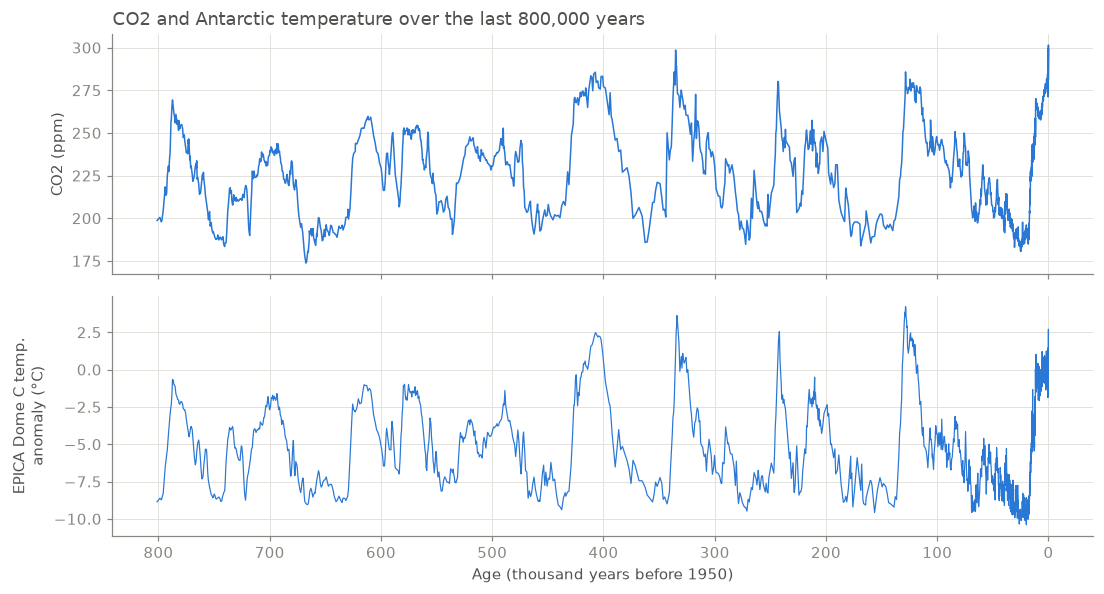

In [29]:
fig, (ax_co2, ax_temp) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
ax_co2.plot(deep["age_kyr"], deep["co2_ppm"], color=BLUE, lw=1)
ax_co2.set_ylabel("CO2 (ppm)")
ax_co2.set_title("CO2 and Antarctic temperature over the last 800,000 years", loc="left")

ax_temp.plot(deep["age_kyr"], deep["temp_anomaly_c"], color=BLUE, lw=0.8)
ax_temp.set_ylabel("EPICA Dome C temp.\nanomaly (°C)")
ax_temp.set_xlabel("Age (thousand years before 1950)")
ax_temp.invert_xaxis()   # oldest on the left, the usual paleoclimate convention
plt.tight_layout()
plt.show()

In [30]:
print(f"CO2 vs EDC temperature, pre-industrial samples: r = {natural.co2_ppm.corr(natural.temp_anomaly_c):.2f} (n = {len(natural)})")

CO2 vs EDC temperature, pre-industrial samples: r = 0.92 (n = 1716)


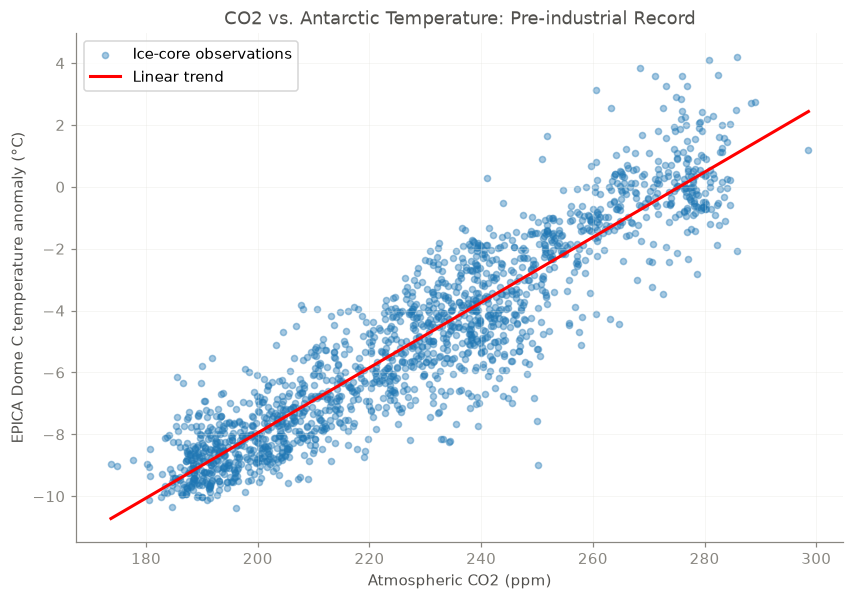

CO2-temperature correlation: 0.924
Number of observations: 1716


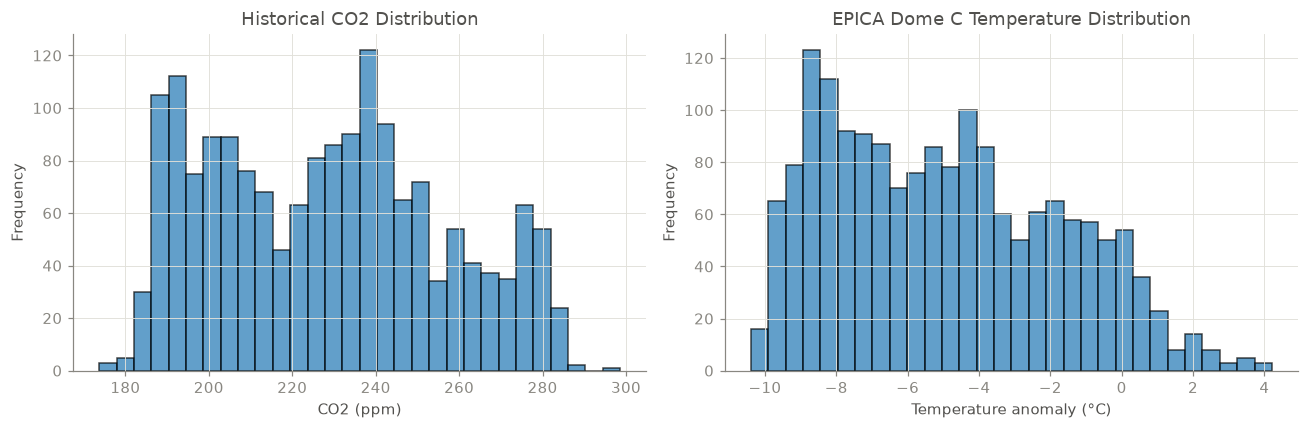

In [31]:

# Additional analysis: CO2 and EPICA Dome C temperature
# Use pre-industrial data to avoid including industrial-era CO2 increases.

analysis_data = natural[
    ["age_bp", "co2_ppm", "temp_anomaly_c"]
].dropna().copy()

# Calculate correlation and linear trend
correlation = analysis_data["co2_ppm"].corr(
    analysis_data["temp_anomaly_c"]
)

slope, intercept = np.polyfit(
    analysis_data["co2_ppm"],
    analysis_data["temp_anomaly_c"],
    1
)

x_line = np.linspace(
    analysis_data["co2_ppm"].min(),
    analysis_data["co2_ppm"].max(),
    100
)

# Plot CO2 versus reconstructed temperature
plt.figure(figsize=(9, 6))

plt.scatter(
    analysis_data["co2_ppm"],
    analysis_data["temp_anomaly_c"],
    alpha=0.4,
    s=16,
    label="Ice-core observations"
)

plt.plot(
    x_line,
    slope * x_line + intercept,
    color="red",
    linewidth=2,
    label="Linear trend"
)

plt.xlabel("Atmospheric CO2 (ppm)")
plt.ylabel("EPICA Dome C temperature anomaly (°C)")
plt.title("CO2 vs. Antarctic Temperature: Pre-industrial Record")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"CO2-temperature correlation: {correlation:.3f}")
print(f"Number of observations: {len(analysis_data)}")

# Compare distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    analysis_data["co2_ppm"],
    bins=30,
    edgecolor="black",
    alpha=0.7
)
axes[0].set_title("Historical CO2 Distribution")
axes[0].set_xlabel("CO2 (ppm)")
axes[0].set_ylabel("Frequency")

axes[1].hist(
    analysis_data["temp_anomaly_c"],
    bins=30,
    edgecolor="black",
    alpha=0.7
)
axes[1].set_title("EPICA Dome C Temperature Distribution")
axes[1].set_xlabel("Temperature anomaly (°C)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()


The pre-industrial Antarctic ice-core record shows a strong positive relationship between atmospheric CO₂ concentration and reconstructed EPICA Dome C temperature (r = 0.924, n = 1,716). Higher CO₂ concentrations generally correspond to warmer Antarctic conditions, while lower concentrations correspond to colder conditions. The histograms show the distributions of both variables across the sampled record. Because temperature values were interpolated, sampling intervals are uneven, and the records use different age chronologies, these results should be interpreted as descriptive relationships rather than evidence of direct causation.

### Uneven sampling

Ice-core samples get much farther apart with age. Older ice is thinned and compressed, so each centimetre holds more time, and the youngest part of the composite comes from Law Dome, a high-snowfall site with thick annual layers. The chart shows the time between neighbouring CO2 samples against age, with both axes on log scales so every part of the record stays readable, and the modern annual record for comparison.

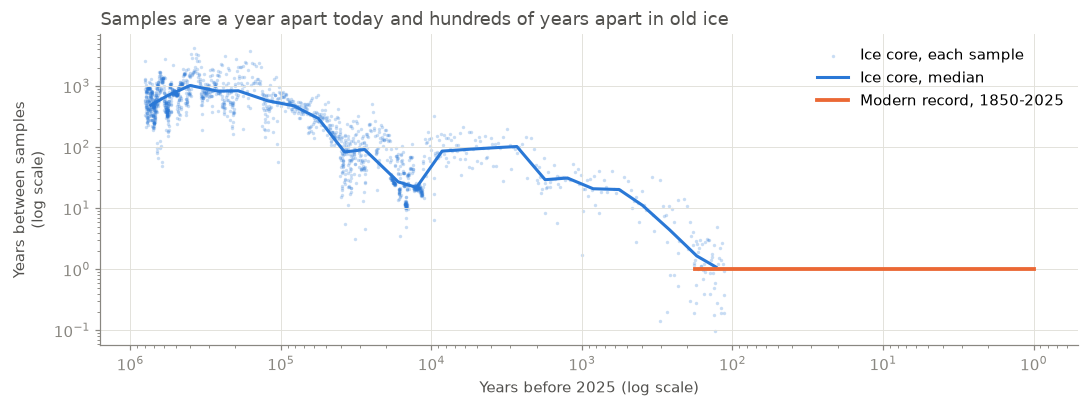

,samples,median_gap_yr
"Modern, 1850-2025",176,1
"Ice core, 0-2 kyr",143,8
"Ice core, 2-20 kyr",369,27
"Ice core, 20-150 kyr",449,189
"Ice core, 150-400 kyr",234,846
"Ice core, 400-801 kyr",587,600


In [32]:
# Time from each sample to the next older one, measured back from 2025 so the modern record fits on the same log axis.
spacing = pd.DataFrame({
    "yr_before_2025": deep["age_bp"] + 75,
    "gap_yr": deep["age_bp"].shift(-1) - deep["age_bp"],
}).dropna()
log_bins = pd.cut(spacing["yr_before_2025"], np.logspace(2, 6, 25))
binned = spacing.groupby(log_bins, observed=True).median()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.scatter(spacing["yr_before_2025"], spacing["gap_yr"], s=5, color=BLUE, alpha=0.25, lw=0, label="Ice core, each sample")
ax.plot(binned["yr_before_2025"], binned["gap_yr"], color=BLUE, lw=2, label="Ice core, median")
ax.plot([1, len(modern)], [1, 1], color=ORANGE, lw=2.5, label="Modern record, 1850-2025")
ax.set_xscale("log")
ax.set_yscale("log")
ax.invert_xaxis()   # oldest on the left, like the other time plots
ax.set_xlabel("Years before 2025 (log scale)")
ax.set_ylabel("Years between samples\n(log scale)")
ax.set_title("Samples are a year apart today and hundreds of years apart in old ice", loc="left")
ax.legend(loc="upper right", frameon=False)
plt.tight_layout()
plt.show()

eras = pd.cut(deep["age_kyr"], [0, 2, 20, 150, 400, 802],
              labels=["Ice core, 0-2 kyr", "Ice core, 2-20 kyr", "Ice core, 20-150 kyr",
                      "Ice core, 150-400 kyr", "Ice core, 400-801 kyr"])
by_era = spacing.assign(era=eras).groupby("era", observed=True)["gap_yr"].agg(samples="size", median_gap_yr="median")
pd.concat([pd.DataFrame({"samples": [len(modern)], "median_gap_yr": [1.0]}, index=["Modern, 1850-2025"]),
           by_era]).round(0).astype(int)

About a quarter of the pre-industrial samples come from the last 20,000 years, which is only 2.5% of the record. That is the sampling bias described under Biased data, and the reason the analysis should average onto an even time grid before computing whole-record statistics.

### Modern records

The four modern series on one time axis, with the catalog eruptions marked.

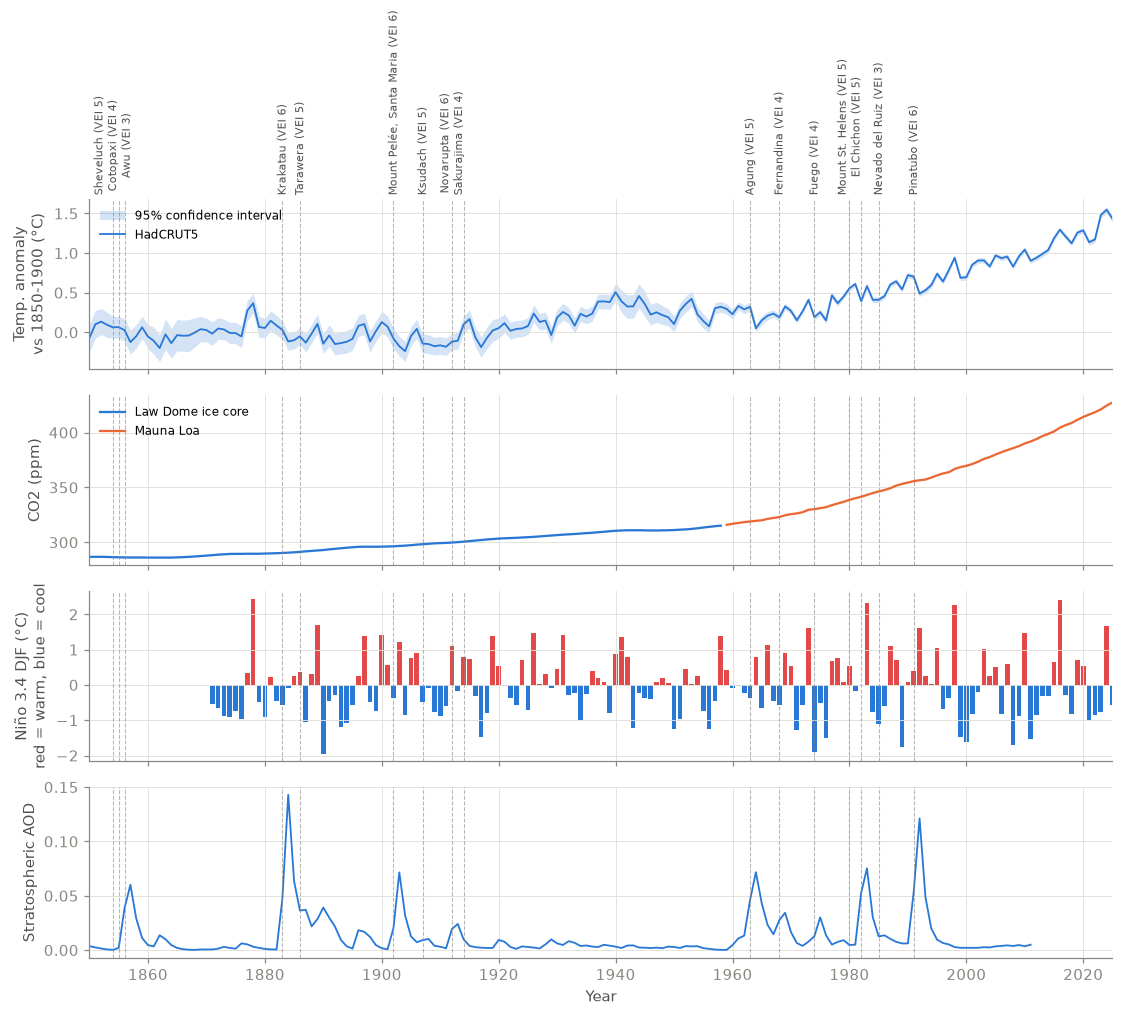

In [33]:
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
axes[0].fill_between(modern.year, modern.temp_ci_low_c, modern.temp_ci_high_c, color=BLUE, alpha=0.2, lw=0,
                     label="95% confidence interval")
axes[0].plot(modern.year, modern.temp_anomaly_c, color=BLUE, lw=1.2, label="HadCRUT5")
axes[0].set_ylabel("Temp. anomaly\nvs 1850-1900 (°C)")
axes[0].legend(loc="upper left", frameon=False, fontsize=8)

for (src, g), color in zip(modern.groupby("co2_source"), [BLUE, ORANGE]):
    axes[1].plot(g.year, g.co2_ppm, color=color, lw=1.5, label=src)
axes[1].set_ylabel("CO2 (ppm)")
axes[1].legend(loc="upper left", frameon=False, fontsize=8)

axes[2].bar(modern.year, modern.nino34_djf_c, width=0.8,
            color=np.where(modern.nino34_djf_c >= 0, RED, BLUE))
axes[2].set_ylabel("Niño 3.4 DJF (°C)\nred = warm, blue = cool")

axes[3].plot(modern.year, modern.volcanic_aod, color=BLUE, lw=1.2)
axes[3].set_ylabel("Stratospheric AOD")

# Eruptions within two years of each other share one stacked label so the text doesn't overlap.
labels = []   # (year to place the label, text, latest year in the group)
for _, ev in events.iterrows():
    for ax in axes:
        ax.axvline(ev.year, color=GRAY, ls="--", lw=0.7, alpha=0.6)
    text = f"{ev.eruption_name} (VEI {ev.max_vei})"
    if labels and ev.year - labels[-1][2] <= 2:
        labels[-1] = (labels[-1][0], labels[-1][1] + "\n" + text, ev.year)
    else:
        labels.append((ev.year, text, ev.year))
for year, text, _ in labels:
    axes[0].text(year, 1.02, text, rotation=90, fontsize=7, color=INK, ha="center", va="bottom",
                 transform=axes[0].get_xaxis_transform())
axes[-1].set_xlabel("Year")
axes[-1].set_xlim(1850, 2025)
fig.subplots_adjust(top=0.80, hspace=0.15)
plt.show()

In [34]:
modern[["temp_anomaly_c", "co2_forcing_wm2", "nino34_djf_c", "volcanic_aod"]].corr().round(2)

,temp_anomaly_c,co2_forcing_wm2,nino34_djf_c,volcanic_aod
temp_anomaly_c,1.00,0.95,0.15,-0.11
co2_forcing_wm2,0.95,1.00,0.02,0.02
nino34_djf_c,0.15,0.02,1.00,0.17
volcanic_aod,-0.11,0.02,0.17,1.00


Across all years, global temperature anomalies show a strong positive correlation with CO₂ radiative forcing (r = 0.95), while December–January–February (DJF) Niño 3.4 temperature anomalies (r = 0.15) and volcanic aerosol optical depth (AOD; r = −0.11) show weak correlations with temperature. AOD measures how much sunlight is scattered or absorbed by atmospheric aerosols. These correlations reflect overall relationships and may not capture short-term climate responses or delayed effects.
When looking more closely at the three volcanic eruptions - Agung (1963), El Chichón (1982), and Pinatubo (1991), we observed El Niño conditions during the following winter, with DJF Niño 3.4 anomalies of +0.79, +2.33, and +1.62°C in 1964, 1983, and 1992, respectively. Volcanic AOD was also elevated during these years, ranging from 0.072 to 0.121. Because El Niño warming and aerosol cooling overlap in the same years, the eruption analysis should account for El Niño–Southern Oscillation (ENSO) variability when comparing temperatures before and after each eruption.

Required DataFrames and columns are available.
Deep-time dataset: (1783, 8)
Modern dataset: (176, 16)

PRE-INDUSTRIAL CO2 DATA
Original sample count: 1,716
Age range: 201 to 801,236 years BP
CO2 concentration range: 173.71 to 298.60 ppm
Mean original sampling interval: 467.08 years
Median original sampling interval: 351.80 years
Overlapping 100-year windows (1-yr step): 800,936
Resolved windows (bracketing samples <= 200 yr apart): 24,041 (3.0%), about 24 kyr of record

MODERN CO2 DATA
Year range: 1850 to 2025
CO2 concentration range: 286.10 to 427.35 ppm
Modern overlapping 100-year intervals: 76

ATMOSPHERIC ΔCO2 OVER 100-YEAR INTERVALS

Descriptive Statistics:
Units: ppm per 100-year interval, except count
Counts are overlapping windows at a 1-year step, so neighbouring windows are not independent.


,Pre-industrial (resolved),Modern
Count,24041.00,76.00
Mean,0.22,62.28
Median,0.08,58.50
Std Dev,2.61,28.68
Minimum,-12.17,24.40
Maximum,17.95,122.65



Latest modern interval: 1925-2025
ΔCO2 over 100 years: +122.65 ppm

MODERN VS. PRE-INDUSTRIAL COMPARISON
Minimum estimated pre-industrial change: -12.17 ppm per 100 years
Maximum estimated pre-industrial increase: +17.95 ppm per 100 years
Latest modern increase: +122.65 ppm per 100 years
Latest modern increase is 6.83 times the estimated pre-industrial maximum increase.

ATMOSPHERIC CO2 CONCENTRATION COMPARISON
Maximum pre-industrial CO2 concentration: 298.60 ppm
Modern CO2 concentration (2025): 427.35 ppm
Difference: +128.75 ppm
Percentage above the pre-industrial maximum: 43.12%

The latest modern CO2 concentration exceeds the observed pre-industrial maximum in this ice-core dataset.

The latest modern 100-year CO2 increase exceeds the maximum estimated pre-industrial 100-year increase in this analysis.

MODAL RANGES
Pre-industrial modal range (1-ppm bins): 0.0 to 1.0 ppm
Modern modal range (10-ppm bins): 30.0 to 40.0 ppm


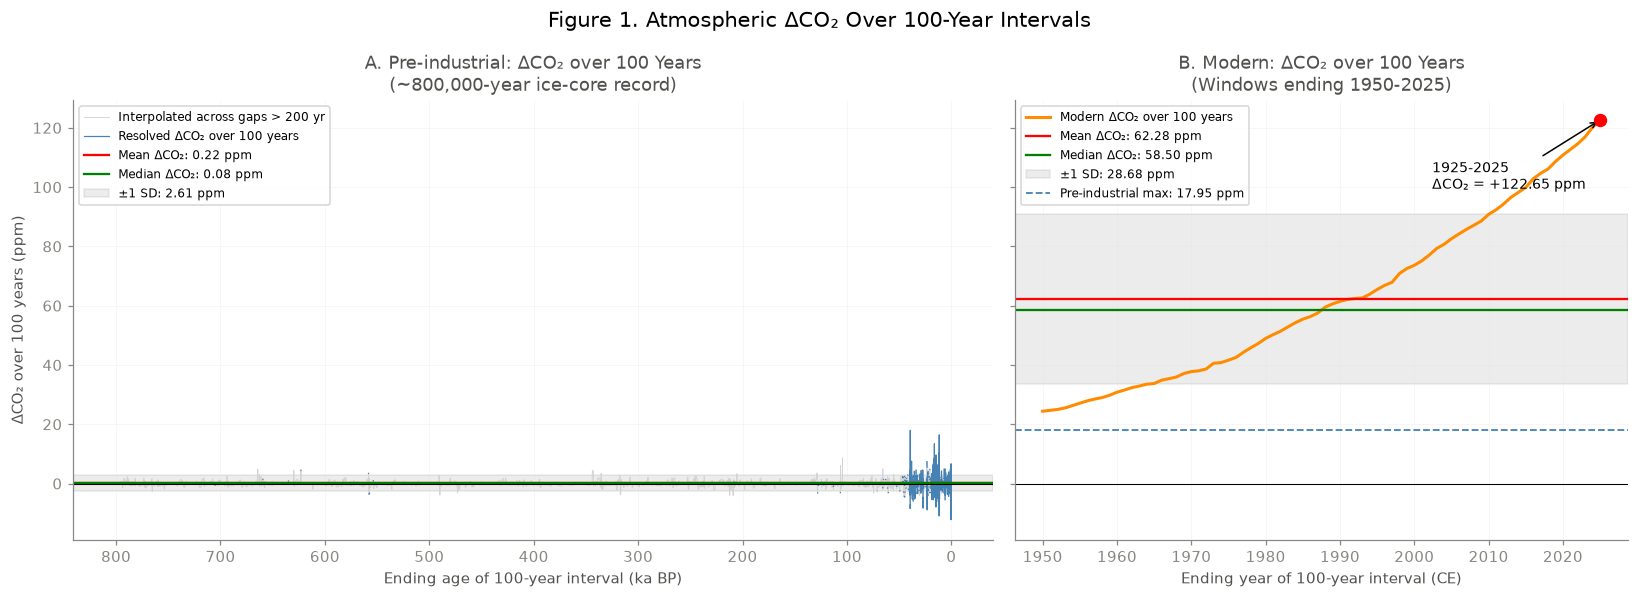

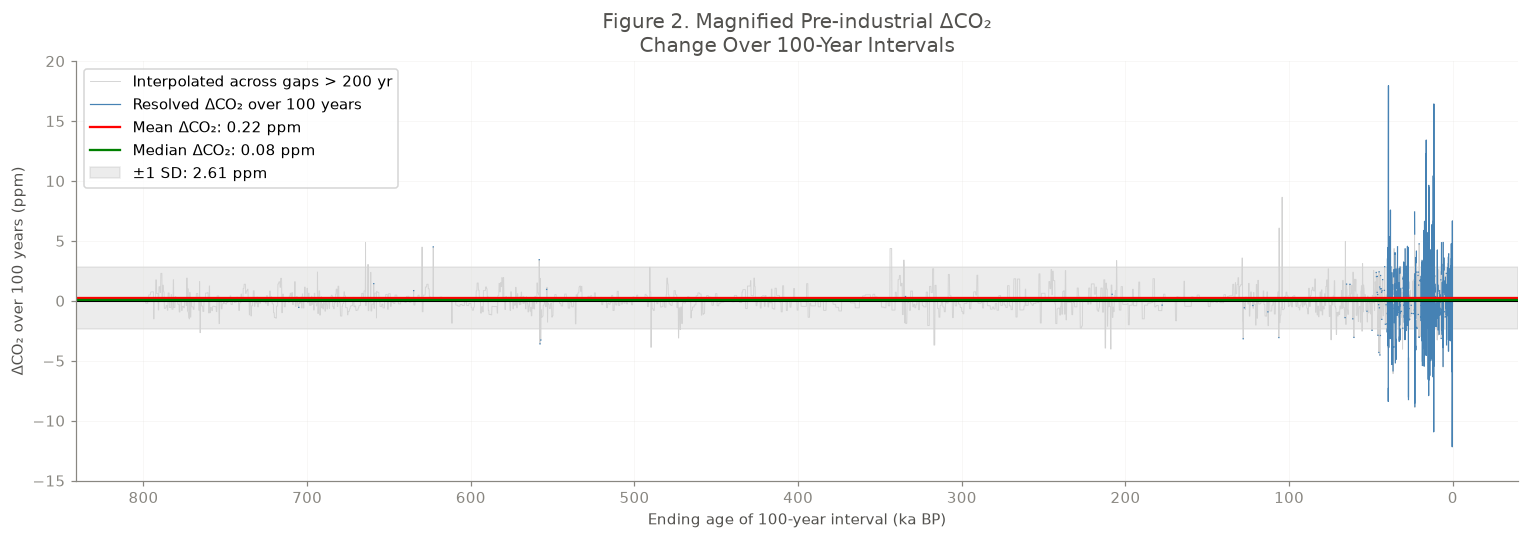

In [35]:

#Post Peer Review Update
# GEOL557A - Modern vs. Pre-industrial CO2 Changes
# Atmospheric CO2 Change Over 100-Year Intervals
# ΔCO2 = CO2(end) - CO2(start)
# Uses the existing clean DataFrames from the
# GEOL557 Group Project Data Wrangling notebook.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

INTERVAL_YEARS = 100


# 1. Check existing DataFrames

if "deep" not in globals() or "modern" not in globals():
    raise RuntimeError(
        "Run the earlier notebook cells to create "
        "'deep' and 'modern' first."
    )

required_deep = [
    "age_bp",
    "co2_ppm",
    "is_preindustrial"
]

required_modern = [
    "year",
    "co2_ppm"
]

for col in required_deep:
    if col not in deep.columns:
        raise ValueError(f"Missing column in deep: {col}")

for col in required_modern:
    if col not in modern.columns:
        raise ValueError(f"Missing column in modern: {col}")

print("Required DataFrames and columns are available.")
print(f"Deep-time dataset: {deep.shape}")
print(f"Modern dataset: {modern.shape}")


# 2. Prepare pre-industrial CO2 data

# Select only pre-industrial samples using the
# existing flag from the data-wrangling notebook.

paleo = deep.loc[
    deep["is_preindustrial"] == 1,
    ["age_bp", "co2_ppm"]
].copy()

paleo = paleo.dropna()

# Average duplicate ages, if present,
# and sort from youngest to oldest.

paleo = (
    paleo.groupby("age_bp", as_index=False)["co2_ppm"]
    .mean()
    .sort_values("age_bp")
)

if len(paleo) < 2:
    raise ValueError("Insufficient pre-industrial CO2 data.")

print("\nPRE-INDUSTRIAL CO2 DATA")
print(f"Original sample count: {len(paleo):,}")

print(
    f"Age range: "
    f"{paleo['age_bp'].min():,.0f} to "
    f"{paleo['age_bp'].max():,.0f} years BP"
)

print(
    f"CO2 concentration range: "
    f"{paleo['co2_ppm'].min():.2f} to "
    f"{paleo['co2_ppm'].max():.2f} ppm"
)

# Examine the temporal resolution of the original samples.

paleo_age_spacing = paleo["age_bp"].diff().dropna()

print(
    f"Mean original sampling interval: "
    f"{paleo_age_spacing.mean():.2f} years"
)

print(
    f"Median original sampling interval: "
    f"{paleo_age_spacing.median():.2f} years"
)

# Estimate overlapping 100-year changes, one window per year,
# the same way as the annual modern record below. With
# non-overlapping windows the maximum depended on where the
# first window started (9.6 to 16.9 ppm across offsets).

STEP_YEARS = 1

# A window is "resolved" when the samples bracketing it are at
# most 200 years apart. Elsewhere, both ends are interpolated
# along a straight line between samples that can be ~900 years
# apart, which flattens any 100-year change toward zero.

MAX_BRACKET_YEARS = 2 * INTERVAL_YEARS

paleo_ages = paleo["age_bp"].to_numpy()
paleo_co2 = paleo["co2_ppm"].to_numpy()

start_ages = np.arange(
    paleo_ages.min(),
    paleo_ages.max() - INTERVAL_YEARS + STEP_YEARS,
    STEP_YEARS
)

start_ages = start_ages[
    start_ages + INTERVAL_YEARS <= paleo_ages.max()
]

if len(start_ages) == 0:
    raise ValueError("No complete pre-industrial 100-year intervals.")

# Interpolate CO2 at the younger and older end of each interval.
# Positive changes mean CO2 increased toward the present.

co2_younger = np.interp(start_ages, paleo_ages, paleo_co2)
co2_older = np.interp(start_ages + INTERVAL_YEARS, paleo_ages, paleo_co2)
paleo_change_all = co2_younger - co2_older

# Nearest sample at or younger than the window start,
# and nearest sample at or older than the window end.

younger_sample = np.searchsorted(paleo_ages, start_ages, side="right") - 1
older_sample = np.searchsorted(
    paleo_ages, start_ages + INTERVAL_YEARS, side="left"
)
bracket_span = paleo_ages[older_sample] - paleo_ages[younger_sample]
is_resolved = bracket_span <= MAX_BRACKET_YEARS

# Statistics and the blue line in the figures use resolved
# windows only; unresolved windows become NaN.

paleo_change = np.where(is_resolved, paleo_change_all, np.nan)

# Ending age of each interval in thousands
# of years before present.

paleo_end_ka = start_ages / 1000

print(
    f"Overlapping 100-year windows ({STEP_YEARS}-yr step): "
    f"{len(start_ages):,}"
)

print(
    f"Resolved windows (bracketing samples <= "
    f"{MAX_BRACKET_YEARS} yr apart): {is_resolved.sum():,} "
    f"({is_resolved.mean():.1%}), about "
    f"{is_resolved.sum() * STEP_YEARS / 1000:,.0f} kyr of record"
)


# 3. Prepare modern CO2 data

modern_co2 = modern[["year", "co2_ppm"]].dropna().copy()

modern_co2["year"] = modern_co2["year"].astype(int)

modern_co2 = (
    modern_co2.groupby("year")["co2_ppm"]
    .mean()
    .sort_index()
)

print("\nMODERN CO2 DATA")

print(
    f"Year range: "
    f"{modern_co2.index.min()} to "
    f"{modern_co2.index.max()}"
)

print(
    f"CO2 concentration range: "
    f"{modern_co2.min():.2f} to "
    f"{modern_co2.max():.2f} ppm"
)

# Match each year with its CO2 value exactly
# 100 years earlier.

earlier_values = modern_co2.reindex(
    modern_co2.index - INTERVAL_YEARS
)

# Calculate overlapping 100-year changes.

modern_change = pd.Series(
    modern_co2.to_numpy() - earlier_values.to_numpy(),
    index=modern_co2.index,
    name="delta_co2_100yr_ppm"
).dropna()

if modern_change.empty:
    raise ValueError("No matching modern 100-year intervals.")

modern_end_year = modern_change.index.to_numpy()

latest_year = int(modern_change.index.max())
start_year = latest_year - INTERVAL_YEARS

latest_change = float(modern_change.loc[latest_year])

print(
    f"Modern overlapping 100-year intervals: "
    f"{len(modern_change):,}"
)


# 4. Descriptive statistics

paleo_values = pd.Series(paleo_change).dropna()
modern_values = modern_change.dropna()


def calculate_stats(values):

    return {
        "Count": len(values),
        "Mean": values.mean(),
        "Median": values.median(),
        "Std Dev": values.std(),
        "Minimum": values.min(),
        "Maximum": values.max()
    }


paleo_stats = calculate_stats(paleo_values)
modern_stats = calculate_stats(modern_values)

summary = pd.DataFrame({
    "Pre-industrial (resolved)": paleo_stats,
    "Modern": modern_stats
})

print("\nATMOSPHERIC ΔCO2 OVER 100-YEAR INTERVALS")

print("\nDescriptive Statistics:")
print("Units: ppm per 100-year interval, except count")
print(
    "Counts are overlapping windows at a 1-year step, "
    "so neighbouring windows are not independent."
)

display(summary.round(2))

print(f"\nLatest modern interval: {start_year}-{latest_year}")
print(f"ΔCO2 over 100 years: {latest_change:+.2f} ppm")


# 5. Compare modern and pre-industrial CO2 changes

natural_max = float(paleo_values.max())
natural_min = float(paleo_values.min())

print("\nMODERN VS. PRE-INDUSTRIAL COMPARISON")

print(
    f"Minimum estimated pre-industrial change: "
    f"{natural_min:+.2f} ppm per 100 years"
)

print(
    f"Maximum estimated pre-industrial increase: "
    f"{natural_max:+.2f} ppm per 100 years"
)

print(
    f"Latest modern increase: "
    f"{latest_change:+.2f} ppm per 100 years"
)

if natural_max > 0:

    increase_ratio = latest_change / natural_max

    print(
        f"Latest modern increase is "
        f"{increase_ratio:.2f} times "
        f"the estimated pre-industrial maximum increase."
    )

# Compare atmospheric CO2 concentration levels.

natural_co2_max = float(paleo["co2_ppm"].max())

latest_co2 = float(modern_co2.loc[latest_year])

print("\nATMOSPHERIC CO2 CONCENTRATION COMPARISON")

print(
    f"Maximum pre-industrial CO2 concentration: "
    f"{natural_co2_max:.2f} ppm"
)

print(
    f"Modern CO2 concentration ({latest_year}): "
    f"{latest_co2:.2f} ppm"
)

print(
    f"Difference: "
    f"{latest_co2 - natural_co2_max:+.2f} ppm"
)

print(
    f"Percentage above the pre-industrial maximum: "
    f"{(latest_co2 / natural_co2_max - 1) * 100:.2f}%"
)

if latest_co2 > natural_co2_max:

    print(
        "\nThe latest modern CO2 concentration exceeds "
        "the observed pre-industrial maximum "
        "in this ice-core dataset."
    )

if latest_change > natural_max:

    print(
        "\nThe latest modern 100-year CO2 increase exceeds "
        "the maximum estimated pre-industrial 100-year "
        "increase in this analysis."
    )


# 6. Modal ranges

# Histogram modal ranges are used because
# CO2 changes are continuous numerical values.

def modal_range(values, bin_width):

    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    edges = np.arange(
        np.floor(values.min() / bin_width) * bin_width,
        np.ceil(values.max() / bin_width) * bin_width
        + bin_width * 1.01,
        bin_width
    )

    counts, edges = np.histogram(values, bins=edges)

    i = np.argmax(counts)

    return edges[i], edges[i + 1]


paleo_mode = modal_range(paleo_values, 1)
modern_mode = modal_range(modern_values, 10)

print("\nMODAL RANGES")

print(
    "Pre-industrial modal range (1-ppm bins): "
    f"{paleo_mode[0]:.1f} to {paleo_mode[1]:.1f} ppm"
)

print(
    "Modern modal range (10-ppm bins): "
    f"{modern_mode[0]:.1f} to {modern_mode[1]:.1f} ppm"
)


# 7. Helper function for statistical reference lines

def add_stats(ax, stats):

    # Mean
    ax.axhline(
        stats["Mean"],
        color="red",
        linestyle="-",
        linewidth=1.5,
        label=f'Mean ΔCO₂: {stats["Mean"]:.2f} ppm'
    )

    # Median
    ax.axhline(
        stats["Median"],
        color="green",
        linestyle="-",
        linewidth=1.5,
        label=f'Median ΔCO₂: {stats["Median"]:.2f} ppm'
    )

    # One standard deviation around the mean
    ax.axhspan(
        stats["Mean"] - stats["Std Dev"],
        stats["Mean"] + stats["Std Dev"],
        color="gray",
        alpha=0.15,
        label=f'±1 SD: {stats["Std Dev"]:.2f} ppm'
    )

    # Zero-change reference line
    ax.axhline(
        0,
        color="black",
        linewidth=0.7
    )

    ax.grid(alpha=0.25)


# 8. Figure 1: Modern vs. Pre-industrial ΔCO2

# Shared y-axis allows direct comparison
# of the magnitude of atmospheric CO2 changes.

fig1, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(15, 5.5),
    sharey=True,
    gridspec_kw={"width_ratios": [1.5, 1]}
)

# Panel A: Pre-industrial

ax1.plot(
    paleo_end_ka,
    paleo_change_all,
    color="lightgray",
    linewidth=0.6,
    label=f"Interpolated across gaps > {MAX_BRACKET_YEARS} yr"
)

ax1.plot(
    paleo_end_ka,
    paleo_change,
    color="steelblue",
    linewidth=0.8,
    label="Resolved ΔCO₂ over 100 years"
)

add_stats(ax1, paleo_stats)

ax1.set_title(
    "A. Pre-industrial: ΔCO₂ over 100 Years\n"
    "(~800,000-year ice-core record)"
)

ax1.set_xlabel(
    "Ending age of 100-year interval (ka BP)"
)

ax1.set_ylabel(
    "ΔCO₂ over 100 years (ppm)"
)

# Display older ages on the left
# and younger ages on the right.

ax1.invert_xaxis()

ax1.legend(
    fontsize=8,
    loc="upper left"
)

# Panel B: Modern

ax2.plot(
    modern_end_year,
    modern_change.to_numpy(),
    color="darkorange",
    linewidth=2,
    label="Modern ΔCO₂ over 100 years"
)

add_stats(ax2, modern_stats)

# Highlight the latest modern 100-year interval.

ax2.scatter(
    latest_year,
    latest_change,
    color="red",
    s=60,
    zorder=5
)

ax2.annotate(
    f"{start_year}-{latest_year}\n"
    f"ΔCO₂ = {latest_change:+.2f} ppm",
    xy=(latest_year, latest_change),
    xytext=(-110, -45),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"},
    fontsize=9
)

# Show the estimated pre-industrial maximum
# as a reference on the modern panel.

ax2.axhline(
    natural_max,
    color="steelblue",
    linestyle="--",
    linewidth=1.2,
    label=f"Pre-industrial max: {natural_max:.2f} ppm"
)

ax2.set_title(
    "B. Modern: ΔCO₂ over 100 Years\n"
    f"(Windows ending {modern_end_year.min()}-"
    f"{modern_end_year.max()})"
)

ax2.set_xlabel(
    "Ending year of 100-year interval (CE)"
)

ax2.legend(
    fontsize=8,
    loc="upper left"
)

fig1.suptitle(
    "Figure 1. Atmospheric ΔCO₂ Over 100-Year Intervals",
    fontsize=14
)

fig1.tight_layout()

plt.show()


# 9. Figure 2: Magnified pre-industrial ΔCO2

fig2, ax3 = plt.subplots(
    figsize=(14, 5)
)

ax3.plot(
    paleo_end_ka,
    paleo_change_all,
    color="lightgray",
    linewidth=0.6,
    label=f"Interpolated across gaps > {MAX_BRACKET_YEARS} yr"
)

ax3.plot(
    paleo_end_ka,
    paleo_change,
    color="steelblue",
    linewidth=0.8,
    label="Resolved ΔCO₂ over 100 years"
)

add_stats(ax3, paleo_stats)

# Magnified y-axis to show smaller historical changes.

ax3.set_ylim(-15, 20)

ax3.invert_xaxis()

ax3.set_title(
    "Figure 2. Magnified Pre-industrial ΔCO₂\n"
    "Change Over 100-Year Intervals",
    fontsize=13
)

ax3.set_xlabel(
    "Ending age of 100-year interval (ka BP)"
)

ax3.set_ylabel(
    "ΔCO₂ over 100 years (ppm)"
)

ax3.legend(
    loc="upper left"
)

fig2.tight_layout()

plt.show()





Post Peer Review
Notes on Modern vs. Pre-industrial CO2 Changes
----------------------------------------------
ΔCO₂ represents the change in atmospheric CO₂ concentration over a 100-year interval.
Pre-industrial ΔCO₂ values are estimates from interpolated ice-core measurements.
Differences in temporal resolution limit direct comparison of modern and historical rates.
The ±1 SD bands show variability in calculated ΔCO₂, not measurement uncertainty.